# 01. EDA trên Train

Đọc bộ chia từ notebook 00 và khảo sát riêng các sinh viên thuộc Train.

**Đầu ra** là bảng, biểu đồ và nhận xét trong notebook. Các bản dùng cho báo cáo được lưu vào `reports/tables/eda_train/` và `reports/figures/eda_train/`.

## Mở dữ liệu

Chọn kernel Python đã cài các thư viện trong `requirements.txt`.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc để notebook đọc đúng file, kể cả khi kernel chạy từ thư mục con.
current = Path.cwd().resolve()
root = next(
    (folder for folder in (current, *current.parents)
     if (folder / "common/preprocessing.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code rồi chạy notebook.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.preprocessing import (
    BINARY_COLUMNS, CATEGORICAL_COLUMNS, FEATURE_COLUMNS, LABELS, NUMERIC_COLUMNS, TARGET,
)

data_path = root / "data/raw/data.csv"
split_path = root / "data/splits/splits.json"
# File UCI ngăn cột bằng dấu chấm phẩy. Xóa khoảng trắng thừa quanh tên cột.
data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()

# Thống nhất ký tự xuống dòng trước khi tính mã nhận diện CSV trên Windows và Linux.
csv_bytes = data_path.read_bytes().replace(b"\r\n", b"\n")
data_hash = hashlib.sha256(csv_bytes).hexdigest()

## 1. Lấy dữ liệu Train

Dùng chỉ số dòng từ splits.json. Kiểm tra mã nhận diện CSV trước khi lấy dữ liệu.

In [2]:
from IPython.display import Image
import matplotlib.pyplot as plt

if not split_path.is_file():
    raise FileNotFoundError("Chạy 00_prepare_data.ipynb để tạo bộ chia.")
split = json.loads(split_path.read_text(encoding="utf-8"))
if split["sha256"] != data_hash or split["n_rows"] != len(data):
    raise ValueError("CSV hiện tại khác bản dùng để tạo bộ chia.")
# Giữ chỉ số dòng CSV gốc để tra các dòng của fold khi thử tiền xử lý.
train = data.iloc[split["train"]].copy()
print(f"EDA trên {len(train):,} sinh viên Train.")

table_dir = root / "reports/tables/eda_train"
figure_dir = root / "reports/figures/eda_train"
table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

def show_and_save(figure, filename):
    path = figure_dir / filename
    figure.tight_layout()
    figure.savefig(path, dpi=160)
    plt.close(figure)
    display(Image(filename=str(path)))

EDA trên 3,096 sinh viên Train.


## 2. Phân bố ba lớp

Đếm số lượng và tỉ lệ từng nhãn trong Train để chọn cách đọc kết quả mô hình.

,count,proportion
Target,,
Dropout,995,32.1%
Enrolled,556,18.0%
Graduate,1545,49.9%


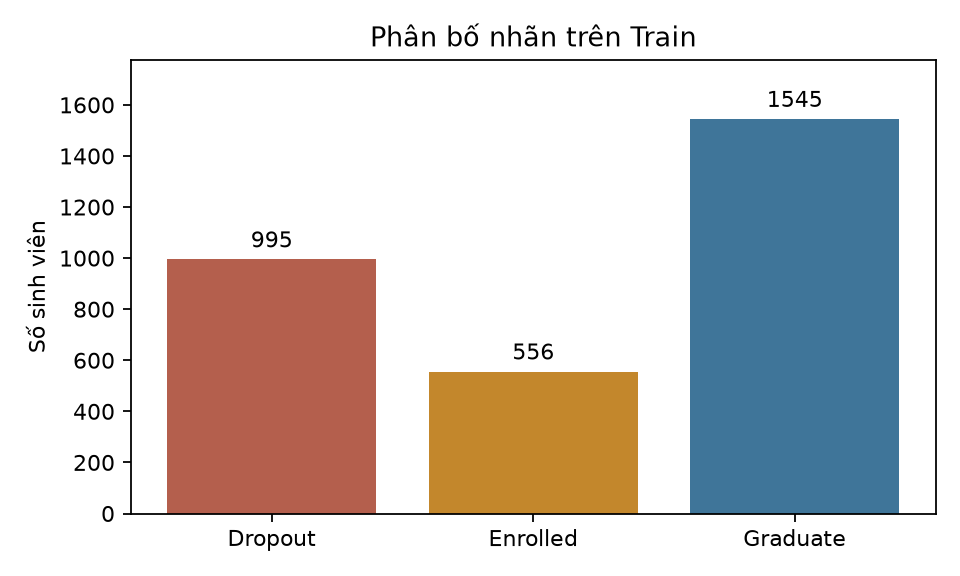

In [3]:
# Dùng cùng thứ tự nhãn cho bảng và biểu đồ để dễ đối chiếu.
counts = train[TARGET].value_counts().reindex(LABELS, fill_value=0)
class_distribution = pd.DataFrame({
    "count": counts, "proportion": counts / len(train),
})
class_distribution.to_csv(table_dir / "class_distribution.csv")
display(class_distribution.assign(proportion=class_distribution["proportion"].map("{:.1%}".format)))

figure, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(counts.index, counts.values, color=["#B45F4D", "#C3872C", "#3F7599"])
ax.bar_label(bars, padding=3)
ax.set(title="Phân bố nhãn trên Train", ylabel="Số sinh viên", ylim=(0, counts.max() * 1.15))
show_and_save(figure, "class_distribution.png")

### Nhận xét

Enrolled là lớp ít nhất (556 mẫu, 18.0%). Graduate có 1,545 mẫu (49.9%). Nhóm dùng **Macro-F1** để ba lớp có trọng số như nhau khi tổng hợp F1, và theo dõi thêm điểm của từng lớp.

## 3. Số học phần được thông qua theo lớp

Dùng boxplot và trung vị để xem kết quả học tập khác nhau thế nào giữa Dropout, Enrolled và Graduate.

,HK1,HK2
Target,,
Dropout,2.0,0.0
Enrolled,5.0,4.0
Graduate,6.0,6.0


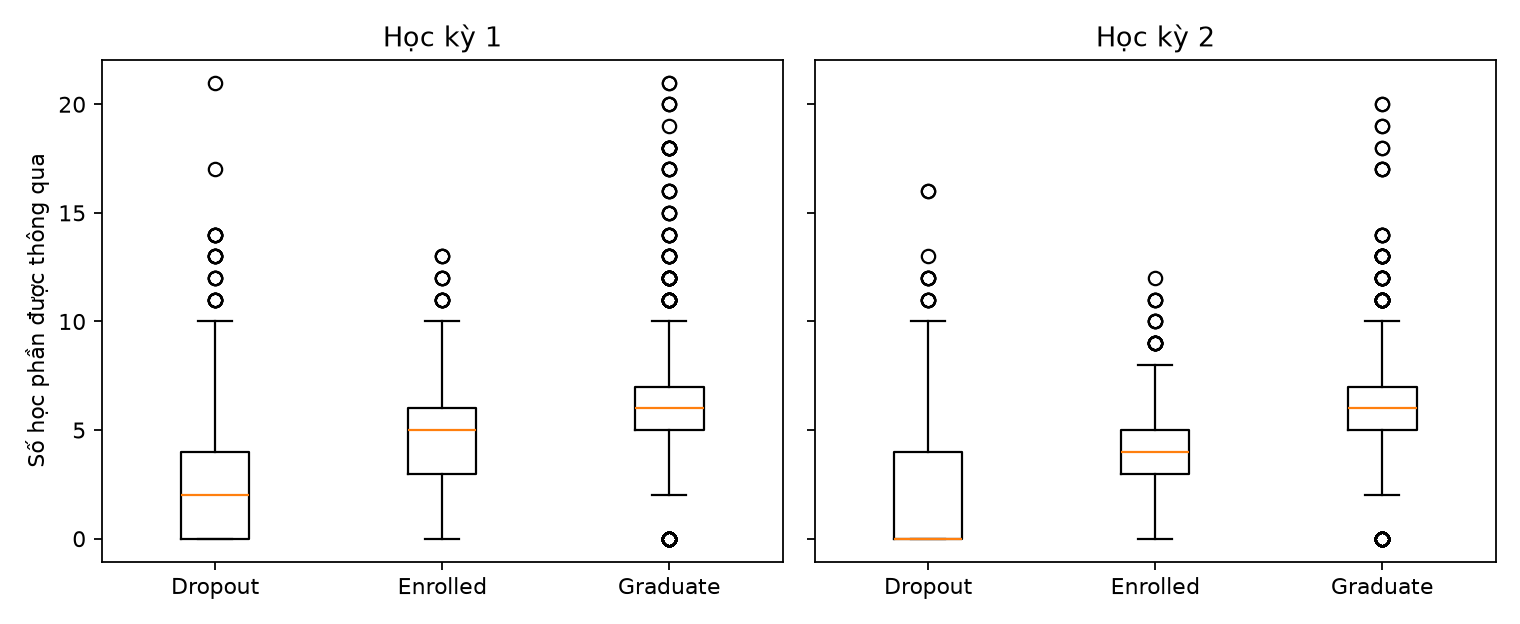

In [4]:
approved = [
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
]
# Gom sinh viên theo nhãn, rồi lấy trung vị số học phần đậu của mỗi học kỳ.
medians = train.groupby(TARGET)[approved].median().reindex(LABELS)
medians = medians.rename(columns=dict(zip(approved, ("HK1", "HK2"))))
medians.to_csv(table_dir / "approved_by_class.csv")
display(medians)

figure, axes = plt.subplots(1, 2, figsize=(9.5, 3.9), sharey=True)
for ax, column, semester in zip(axes, approved, ("Học kỳ 1", "Học kỳ 2")):
    values = [train.loc[train[TARGET].eq(label), column].dropna() for label in LABELS]
    ax.boxplot(values, tick_labels=LABELS)
    ax.set_title(semester)
axes[0].set_ylabel("Số học phần được thông qua")
show_and_save(figure, "approved_by_class.png")

### Nhận xét

Trung vị số học phần được thông qua ở HK2 là Dropout 0, Enrolled 4, Graduate 6. Số học phần đậu thể hiện khác biệt giữa các nhóm trên Train. Giá trị 0 ở cột này được giữ là số học phần đậu bằng 0. Thí nghiệm dùng biến HK2 cần ghi rõ mốc dự đoán có thông tin học kỳ 2.

## 4. Tình trạng học phí và Dropout

Tính tỉ lệ Dropout riêng trong mỗi nhóm học phí, với mẫu số là số sinh viên của nhóm đó.

,dropout_count,total,dropout_rate
Tuition fees up to date,,,
0,320,368,87.0%
1,675,2728,24.7%


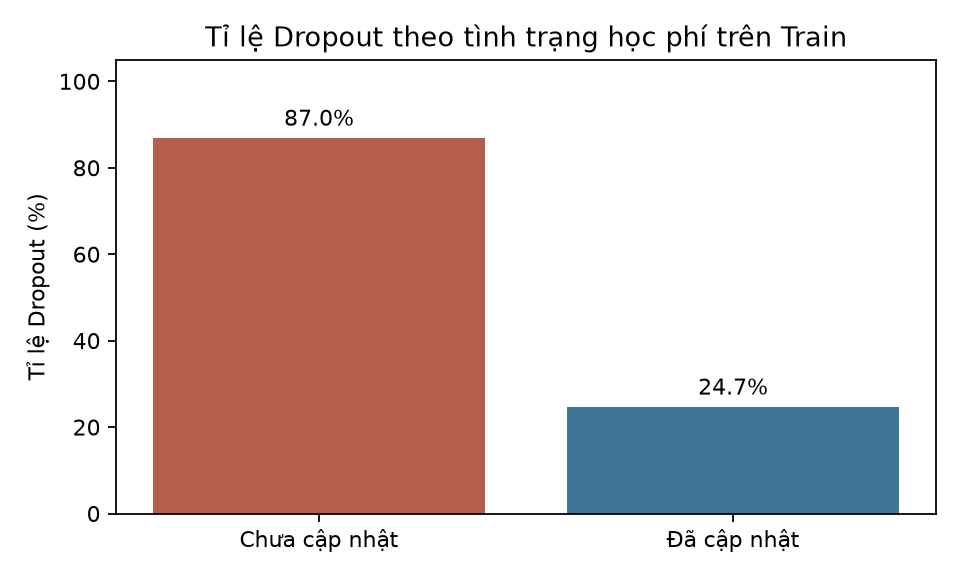

In [5]:
# Trong mỗi nhóm học phí, đếm số sinh viên Dropout và tổng số sinh viên.
tuition = (
    train.assign(is_dropout=train[TARGET].eq("Dropout"))
    .groupby("Tuition fees up to date")["is_dropout"]
    .agg(dropout_count="sum", total="size")
    .reindex([0, 1])
)
# Mẫu số là tổng số sinh viên của chính nhóm học phí đó.
tuition["dropout_rate"] = tuition["dropout_count"] / tuition["total"]
tuition.to_csv(table_dir / "tuition_dropout.csv")
display(tuition.assign(dropout_rate=tuition["dropout_rate"].map("{:.1%}".format)))

figure, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["Chưa cập nhật", "Đã cập nhật"], tuition["dropout_rate"] * 100,
              color=["#B45F4D", "#3F7599"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Tỉ lệ Dropout theo tình trạng học phí trên Train",
       ylabel="Tỉ lệ Dropout (%)", ylim=(0, 105))
show_and_save(figure, "tuition_dropout.png")

### Nhận xét

Nhóm chưa cập nhật học phí có 320/368 sinh viên Dropout (87.0%). Nhóm đã cập nhật có 675/2,728 (24.7%). Đây là mối liên hệ quan sát được trên Train. Để dùng biến này cho một mốc dự đoán cụ thể, cần biết thời điểm ghi nhận học phí.

## 5. Bảng nhóm cột và cách xử lý

Dùng định nghĩa cột để tách số đo, mã nhóm và cờ 0/1. Application order giữ được thứ tự nguyện vọng.

In [6]:
column_groups = pd.DataFrame([
    {"column": column, "group": group, "missing_on_train": int(train[column].isna().sum()),
     "distinct_on_train": int(train[column].nunique())}
    for group, columns in [
        ("numeric", NUMERIC_COLUMNS),
        ("categorical", CATEGORICAL_COLUMNS),
        ("binary", BINARY_COLUMNS),
    ]
    for column in columns
])
column_groups.to_csv(table_dir / "column_groups.csv", index=False)
display(column_groups.groupby("group").agg(
    number_of_columns=("column", "size"), missing_cells=("missing_on_train", "sum"),
))
display(column_groups)

,number_of_columns,missing_cells
group,,
binary,8,0
categorical,9,0
numeric,19,0


,column,group,missing_on_train,distinct_on_train
0,Application order,numeric,0,7
1,Previous qualification (grade),numeric,0,97
2,Admission grade,numeric,0,576
3,Age at enrollment,numeric,0,45
4,Curricular units 1st sem (credited),numeric,0,20
5,Curricular units 1st sem (enrolled),numeric,0,22
6,Curricular units 1st sem (evaluations),numeric,0,31
7,Curricular units 1st sem (approved),numeric,0,22
8,Curricular units 1st sem (grade),numeric,0,621
9,Curricular units 1st sem (without evaluations),numeric,0,11


## 6. Thử tiền xử lý trên một fold

Cột số dùng trung vị nếu thiếu và chuẩn hóa khi bật `scale_numeric`. Cột phân loại dùng one-hot. Cột nhị phân giữ 0/1. Target được tách riêng.

Ví dụ dưới đây fit trên bốn phần dùng để học trong **fold 1**, rồi transform phần chấm của fold đó. Khi viết Logistic/RF, đặt bộ xử lý bên trong pipeline CV. MLP có thể fit bộ xử lý trên toàn bộ Train và transform Validation bằng bộ đã fit.

In [7]:
from common.preprocessing import make_preprocessor

first_fold = split["folds"][0]
# Lấy dòng theo chỉ số CSV đã lưu và chỉ chọn các cột đầu vào X.
X_fit = train.loc[first_fold["train"], list(FEATURE_COLUMNS)]
X_score = train.loc[first_fold["validation"], list(FEATURE_COLUMNS)]
preprocessor = make_preprocessor(scale_numeric=True)

# Học trung vị, thang đo và mã ngành từ phần fit, rồi biến đổi phần fit.
fit_features = preprocessor.fit_transform(X_fit)
# Dùng lại bộ xử lý đã fit để biến đổi phần chấm.
score_features = preprocessor.transform(X_score)
if fit_features.shape[1] != score_features.shape[1] or not np.isfinite(score_features).all():
    raise ValueError("Kiểm tra lại dữ liệu sau tiền xử lý.")

print("Kích thước sau xử lý — phần fit:", fit_features.shape)
print("Kích thước sau xử lý — phần chấm:", score_features.shape)
print("Ví dụ tên đặc trưng:", preprocessor.get_feature_names_out()[:6].tolist())

Kích thước sau xử lý — phần fit: (2476, 226)
Kích thước sau xử lý — phần chấm: (620, 226)
Ví dụ tên đặc trưng: ['numeric__Application order', 'numeric__Previous qualification (grade)', 'numeric__Admission grade', 'numeric__Age at enrollment', 'numeric__Curricular units 1st sem (credited)', 'numeric__Curricular units 1st sem (enrolled)']


## Bàn giao

Chia sẻ `splits.json`, bảng nhóm cột và hàm `make_preprocessor()`. Logistic/MLP dùng `scale_numeric=True`, RF dùng `scale_numeric=False`. Mỗi lượt huấn luyện tạo và fit bộ xử lý theo dữ liệu của lượt đó.